In [10]:
%load_ext autoreload
%autoreload 2

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [11]:
import sys
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter
import numpy as np
from tqdm import tqdm

from pathlib import Path
sys.path.append(str(Path.cwd().parents[0] / "src"))
from plotting import *
from HeteroBilayer import HeteroBilayer
import utils
import analytic_metric

In [12]:
plt.rcParams.update({
    'figure.figsize': (7, 5),
    'figure.dpi': 120,          # crisper on screen
    'savefig.dpi': 300,         # high-res when saving
    'font.size': 12,
    'axes.titlesize': 14,
    'axes.spines.top': False,   # remove top/right borders
    'axes.spines.right': False,
    'axes.grid': False,
    'lines.linewidth': 2,
    'xtick.labelsize': 16,
    'ytick.labelsize': 16,
    "text.usetex": False,
    "mathtext.fontset": "cm",
    "font.family": "serif",
})

# Triangular lattice

### Shifting Wannier functions

In [40]:
sys = HeteroBilayer(theta_deg=2.0, psi_deg=26, V=6.6, n_shells=8)

Text(0.5, 1.0, '$\\mathbf{R}_0 = \\mathbf{a}_2$')

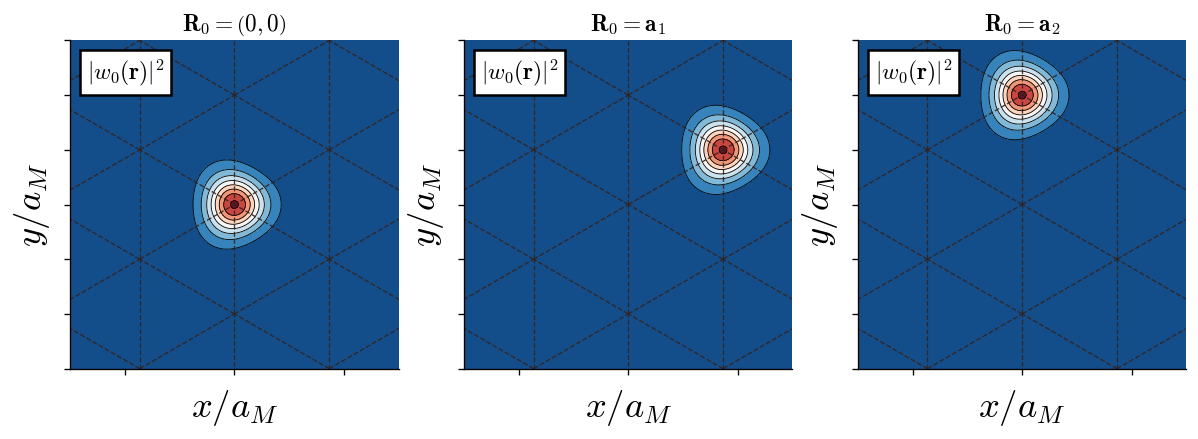

In [41]:
scale = 1.5
k_points = sys.mesh_k_unit_cell()
x = np.linspace(-scale, scale, 300)
y = np.linspace(-scale, scale, 300)
X, Y = np.meshgrid(x, y)

fig, ax = plt.subplots(1, 3, figsize=(12, 8))

im = plot_wannier_function(sys, ax[0], X, Y, k_points, cmap='RdBu_r')
ax[0].set_title(r"$\mathbf{R}_0 = \left(0, 0\right)$")

im = plot_wannier_function(sys, ax[1], X, Y, k_points, R0=sys.a1)
ax[1].set_title(r"$\mathbf{R}_0 = \mathbf{a}_1$")

im = plot_wannier_function(sys, ax[2], X, Y, k_points, R0=sys.a2)
ax[2].set_title(r"$\mathbf{R}_0 = \mathbf{a}_2$")

### Hopping integrals

In [36]:
thetas = np.linspace(0.5, 3.0, 5)
t1 = []
t2 = []
t3 = []

scale = 4.0

Nx = 50
Ny = 50

for th in tqdm(thetas):
    sys.theta_deg = th
    k_points = sys.mesh_k_unit_cell(Nx=15, Ny=15)

    x = np.linspace(-scale, scale, Nx)
    y = np.linspace(-scale, scale, Ny)
    X, Y = np.meshgrid(x, y)

    hoppings = sys.hopping_1band(X, Y, k_points, orders=[1, 2, 3])
    
    t1.append(hoppings[0])
    t2.append(hoppings[1])
    t3.append(hoppings[2])

100%|██████████| 5/5 [00:10<00:00,  2.18s/it]


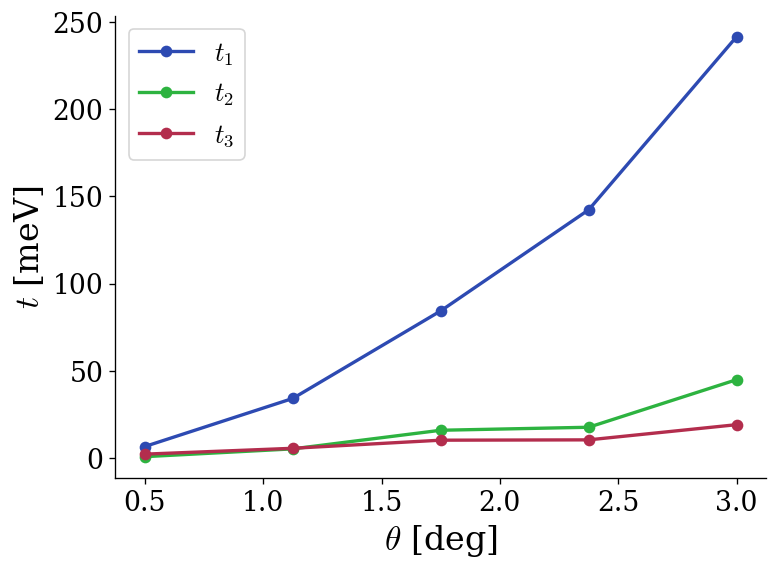

In [37]:
fig, ax = plt.subplots()

cols = ["#2D4AB2", "#2DB340", "#B32D4D"]

ax.plot(thetas, t1, marker="o", label=r"$t_1$", color=cols[0])
ax.plot(thetas, t2, marker="o", label=r"$t_2$", color=cols[1])
ax.plot(thetas, t3, marker="o", label=r"$t_3$", color=cols[2])
ax.set_xlabel(r"$\theta$ [deg]", fontsize=20)
ax.set_ylabel(r"$t$ [meV]", fontsize=20)
ax.legend(fontsize=16)

### Coulomb interactions

In [74]:
thetas = np.linspace(0.5, 3.0, 5)
U0 = []
U1 = []
U2 = []

scale = 4.0

Nx = 80
Ny = 80

for th in tqdm(thetas):
    sys.theta_deg = th
    k_points = sys.mesh_k_unit_cell(Nx=15, Ny=15)

    x = np.linspace(-scale, scale, Nx)
    y = np.linspace(-scale, scale, Ny)
    X, Y = np.meshgrid(x, y)

    interactions = sys.interaction_1band(X, Y, k_points, orders=[0, 1, 2])

    # Coulomb matrix elements in eV
    U0.append(sys.epsilon * interactions[0] / 1000)
    U1.append(sys.epsilon * interactions[1] / 1000)
    U2.append(sys.epsilon * interactions[2] / 1000)

100%|██████████| 5/5 [01:07<00:00, 13.60s/it]


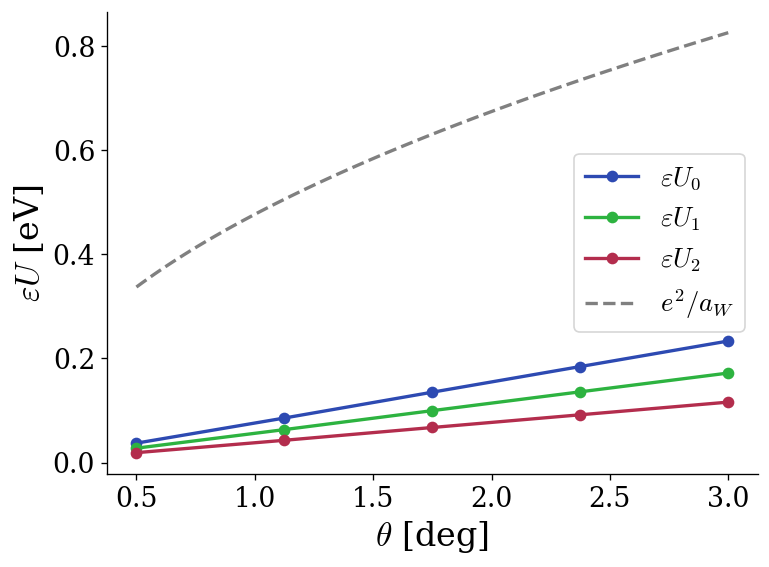

In [73]:
fig, ax = plt.subplots()

cols = ["#2D4AB2", "#2DB340", "#B32D4D"]

ax.plot(thetas, U0, marker="o", label=r"$\varepsilon U_0$", color=cols[0])
ax.plot(thetas, U1, marker="o", label=r"$\varepsilon U_1$", color=cols[1])
ax.plot(thetas, U2, marker="o", label=r"$\varepsilon U_2$", color=cols[2])

tt = np.linspace(0.5, 3.0, 100)
aMs = sys.a0 / (2 * np.sin(np.radians(tt) / 2))
ax.plot(tt, sys.E_SQUARED / (utils.spread_harmonic_approx(aMs, sys.V, sys.psi) * 1000),
       color="gray", linestyle="--", label=r"$e^2/a_W$", linewidth=2)

ax.set_xlabel(r"$\theta$ [deg]", fontsize=20)
ax.set_ylabel(r"$\varepsilon U$ [eV]", fontsize=20)
ax.legend(fontsize=16)